In [1]:
# Student Performance Prediction System
# Day 19: Model Comparison and Best Model Selection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 55)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 19: MODEL COMPARISON AND BEST MODEL SELECTION")
print("=" * 55)

print("Libraries imported successfully!")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 19: MODEL COMPARISON AND BEST MODEL SELECTION
Libraries imported successfully!


In [2]:
# Step 2: Create Student Performance Dataset

data = {
    "Study_Hours": [2, 3, 4, 5, 6, 1, 7, 8, 3, 5, 6, 2, 9, 4, 7],
    "Attendance": [60, 70, 75, 80, 85, 50, 90, 95, 65, 78, 88, 55, 98, 72, 92],
    "Previous_Marks": [45, 50, 55, 60, 65, 35, 75, 85, 48, 62, 70, 40, 90, 58, 80],
    "Final_Marks": [48, 52, 58, 65, 70, 38, 78, 88, 50, 64, 73, 42, 94, 60, 83]
}

df = pd.DataFrame(data)

print("Student dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Student dataset created successfully!
Dataset shape: (15, 4)


,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,2,60,45,48
1,3,70,50,52
2,4,75,55,58
3,5,80,60,65
4,6,85,65,70


In [3]:
# Step 3: Separate Features and Target

X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Final_Marks"]

print("Features selected successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget column:")
print(y.name)

Features selected successfully!
Features shape: (15, 3)
Target shape: (15,)

Feature columns:
['Study_Hours', 'Attendance', 'Previous_Marks']

Target column:
Final_Marks


In [4]:
# Step 4: Split Data into Training and Testing Sets

np.random.seed(42)

indices = np.random.permutation(len(X))

test_size = 3
test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_array = X.to_numpy(dtype=float)
y_array = y.to_numpy(dtype=float)

X_train = X_array[train_indices]
X_test = X_array[test_indices]

y_train = y_array[train_indices]
y_test = y_array[test_indices]

print("Data splitting completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Data splitting completed successfully!
Training samples: 12
Testing samples: 3
Training features shape: (12, 3)
Testing features shape: (3, 3)


In [5]:
# Step 5: Train Linear Regression Model

X_train_with_intercept = np.column_stack([
    np.ones(len(X_train)),
    X_train
])

linear_coefficients = np.linalg.lstsq(
    X_train_with_intercept,
    y_train,
    rcond=None
)[0]

print("Linear Regression model trained successfully!")

print("Intercept:", round(linear_coefficients[0], 4))
print("Feature coefficients:", np.round(linear_coefficients[1:], 4))

Linear Regression model trained successfully!
Intercept: 11.5949
Feature coefficients: [ 2.4825 -0.0039  0.6708]


In [6]:
# Step 6: Train Polynomial Regression Model

def create_polynomial_features(X):
    return np.column_stack([
        X,
        X[:, 0] ** 2,
        X[:, 1] ** 2,
        X[:, 2] ** 2
    ])

X_train_poly = create_polynomial_features(X_train)

X_train_poly_with_intercept = np.column_stack([
    np.ones(len(X_train_poly)),
    X_train_poly
])

poly_coefficients = np.linalg.lstsq(
    X_train_poly_with_intercept,
    y_train,
    rcond=None
)[0]

print("Polynomial Regression model trained successfully!")
print("Number of model coefficients:", len(poly_coefficients))

Polynomial Regression model trained successfully!
Number of model coefficients: 7


In [7]:
# Step 7: Generate Predictions

# Linear Regression predictions
X_test_with_intercept = np.column_stack([
    np.ones(len(X_test)),
    X_test
])

linear_predictions = X_test_with_intercept @ linear_coefficients

# Polynomial Regression predictions
X_test_poly = create_polynomial_features(X_test)

X_test_poly_with_intercept = np.column_stack([
    np.ones(len(X_test_poly)),
    X_test_poly
])

polynomial_predictions = (
    X_test_poly_with_intercept @ poly_coefficients
)

# Compare actual and predicted marks
comparison_df = pd.DataFrame({
    "Actual_Marks": y_test,
    "Linear_Regression": np.round(linear_predictions, 2),
    "Polynomial_Regression": np.round(polynomial_predictions, 2)
})

print("Predictions generated successfully!")
comparison_df

Predictions generated successfully!


,Actual_Marks,Linear_Regression,Polynomial_Regression
0,64.0,65.29,64.99
1,42.0,43.18,43.72
2,48.0,46.51,45.69


In [9]:
# Step 8: Evaluate Both Regression Models

def calculate_metrics(actual, predicted):
    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)

    return mae, mse, rmse


# Calculate Linear Regression metrics
linear_mae, linear_mse, linear_rmse = calculate_metrics(
    y_test, linear_predictions
)

# Calculate Polynomial Regression metrics
poly_mae, poly_mse, poly_rmse = calculate_metrics(
    y_test, polynomial_predictions
)


# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [linear_mae, poly_mae],
    "MSE": [linear_mse, poly_mse],
    "RMSE": [linear_rmse, poly_rmse]
})

model_comparison[["MAE", "MSE", "RMSE"]] = (
    model_comparison[["MAE", "MSE", "RMSE"]].round(3)
)

print("MODEL EVALUATION RESULTS")
print("=" * 45)

model_comparison

MODEL EVALUATION RESULTS


,Model,MAE,MSE,RMSE
0,Linear Regression,1.320,1.758,1.326
1,Polynomial Regression,1.674,3.093,1.759


In [10]:
# Step 9: Select the Best Model

if linear_rmse < poly_rmse:
    best_model_name = "Linear Regression"
    best_rmse = linear_rmse

elif poly_rmse < linear_rmse:
    best_model_name = "Polynomial Regression"
    best_rmse = poly_rmse

else:
    best_model_name = "Both models have equal RMSE"
    best_rmse = linear_rmse


print("BEST MODEL SELECTION")
print("=" * 35)

print("Selected Model:", best_model_name)
print(f"Best RMSE: {best_rmse:.3f}")

print("\nSelection Criteria:")
print("The model with the lower RMSE is selected.")

BEST MODEL SELECTION
Selected Model: Linear Regression
Best RMSE: 1.326

Selection Criteria:
The model with the lower RMSE is selected.


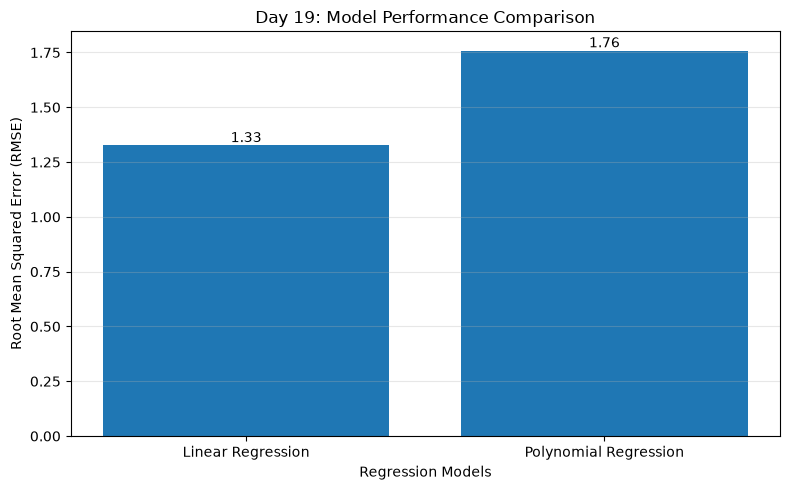

In [11]:
# Step 10: Visualize Model Performance Comparison

models = [
    "Linear Regression",
    "Polynomial Regression"
]

rmse_values = [
    linear_rmse,
    poly_rmse
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, rmse_values)

plt.ylabel("Root Mean Squared Error (RMSE)")
plt.xlabel("Regression Models")
plt.title("Day 19: Model Performance Comparison")

plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [12]:
# Step 11: Save Model Comparison Report

report_path = "day19_model_comparison_report.csv"

model_comparison.to_csv(report_path, index=False)

print("Model comparison report saved successfully!")
print("File name:", report_path)

print("\nReport Preview:")
print(model_comparison.to_string(index=False))

Model comparison report saved successfully!
File name: day19_model_comparison_report.csv

Report Preview:
                Model   MAE   MSE  RMSE
    Linear Regression 1.320 1.758 1.326
Polynomial Regression 1.674 3.093 1.759


In [13]:
# Step 12: Final Project Summary

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 19: MODEL COMPARISON AND BEST MODEL SELECTION")
print("=" * 60)

print("\n1. Dataset Information")
print("Total Students:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\n2. Model Performance Comparison")
print(model_comparison.to_string(index=False))

print("\n3. Best Model Selection")
print("Selected Model:", best_model_name)
print(f"Best RMSE: {best_rmse:.3f}")

print("\n4. Evaluation Metrics")
print("MAE  - Mean Absolute Error")
print("MSE  - Mean Squared Error")
print("RMSE - Root Mean Squared Error")

print("\n5. Conclusion")
print("Two regression models were trained and compared.")
print("The model with lower RMSE was selected on the test set.")
print("More student records are needed for reliable evaluation.")

print("\nDay 19 completed successfully!")
print("=" * 60)

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 19: MODEL COMPARISON AND BEST MODEL SELECTION

1. Dataset Information
Total Students: 15
Training Samples: 12
Testing Samples: 3

2. Model Performance Comparison
                Model   MAE   MSE  RMSE
    Linear Regression 1.320 1.758 1.326
Polynomial Regression 1.674 3.093 1.759

3. Best Model Selection
Selected Model: Linear Regression
Best RMSE: 1.326

4. Evaluation Metrics
MAE  - Mean Absolute Error
MSE  - Mean Squared Error
RMSE - Root Mean Squared Error

5. Conclusion
Two regression models were trained and compared.
The model with lower RMSE was selected on the test set.
More student records are needed for reliable evaluation.

Day 19 completed successfully!
